# Assignment 2. Data Preparation & EDA

**Проект:** HSE AI Analytics — AI-аналитика охраны труда (по ТЗ хакатона)

План notebook (в том же порядке, что и в задании):

1. Описание датасета и исследовательская постановка
2. Загрузка → структура → размер
3. Качество данных: пропуски, дубли, некорректные значения (с количественной оценкой)
4. Очистка (до / после)
5. EDA + визуализация (≥ 5 графиков, ≥ 5 наблюдений)
6. Признаки и target, проверка утечки данных
7. Train / validation / test
8. Научная интерпретация

> Notebook запускается целиком: **Restart → Run All**. Пути относительные, ручных правок не нужно.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import (load_raw, load_reference, clean_incidents, clean_korgau,
                      monthly_counts, INCIDENT_TYPES)
from src.features import build_org_month, split_period, FEATURES, TARGET
from src.plotting import set_style, TYPE_COLORS, KIND_COLORS, MAIN, MUTED, PALETTE

set_style()
pd.set_option("display.max_colwidth", 110)
np.random.seed(42)

## 1. Датасет и исследовательская постановка

| Параметр | Значение |
|---|---|
| **Источник** | Синтетические данные по структуре ТЗ хакатона «Внедрение ИИ в сфере Охраны Труда» (раздел 4.1 разрешает синтетику). Генератор: `data_generation/generate_data.py`, seed = 42 |
| **Предметная область** | Охрана труда и промышленная безопасность (HSE) нефтегазовой компании |
| **Происхождение** | Два модуля ИС «Охрана труда»: журнал **Происшествий** и журнал наблюдений **Карта Коргау** (поведенческие аудиты) |
| **Период** | 01.09.2023 — 31.08.2026 (3 года) |
| **Назначение** | Прогноз происшествий, оценка риска организаций, классификация текстов |
| **Первоисточник** | `docs/TZ_hackathon_HSE.docx` |

**Почему датасет подходит.** Он повторяет поля ТЗ: есть дата (временной ряд), организация и локация (risk scoring), текст описания (NLP). Объёмы взяты из табл. 8.1 ТЗ.

**Проблема.** Сейчас безопасностью управляют реактивно: событие разбирают после того, как оно случилось.
**Цель исследования.** Проверить, можно ли по историческим данным предсказывать происшествия заранее.

**Research Questions**
- **RQ1.** Есть ли во временном ряду происшествий тренд и сезонность, которые позволяют прогнозировать его лучше наивной модели?
- **RQ2.** Предшествует ли рост нарушений Коргау росту происшествий в той же организации?
- **RQ3.** Различаются ли тексты разных типов происшествий настолько, чтобы классифицировать их автоматически?

**Гипотеза H1:** доля плохих практик в организации в месяце *t−1* положительно связана с числом происшествий в месяце *t*.

## 2. Загрузка, структура, размер

In [2]:
inc_raw, kor_raw = load_raw()
orgs = load_reference("organizations")
types_ref = load_reference("incident_types")
print("incidents:", inc_raw.shape, "| korgau:", kor_raw.shape, "| organizations:", orgs.shape)
inc_raw.head(3)

incidents: (1508, 8) | korgau: (4379, 7) | organizations: (14, 5)


,id,date,type,org_id,location,description,cause,status
0,63613650-b24b-4e18-8675-1ce839951e13,2025-01-03 19:30:00,Опасная ситуация,ORG-01,Линейная часть трубопровода,"03.01.2025 (19:30), Линейная часть трубопровода: при разгрузке слесарь был в обуви без защитного подноска,...",Непосредственная причина: Неприменение средств защиты слуха. Коренная причина: Плохая коммуникация в бригаде.,Закрытое
1,0f7ae0c1-6ea6-49b3-9633-df9352d3444a,2026-01-22 01:57:00,Микротравма,ORG-08,Буровая площадка,"22.01.2026 (01:57), Буровая площадка: стропальщик руководил подъёмом трубы, груз выскользнул из строп. Пос...",Непосредственная причина: Нахождение людей под грузом. Коренная причина: Спешка из-за сжатых сроков.,Закрытое
2,4362170d-9f65-4399-a994-9a1045ffac08,2024-08-12 14:07:00,Опасная ситуация,ORG-09,Линейная часть трубопровода,12.08.2024 в 14:07 на объекте «Линейная часть трубопровода» газосварщик при работе на лесах на высоте окол...,Непосредственная причина: Отсутствие ограждения рабочей площадки. Коренная причина: Недостаточная квалифик...,Закрытое


In [3]:
inc_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1508 entries, 0 to 1507
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   id           1508 non-null   str  
 1   date         1508 non-null   str  
 2   type         1508 non-null   str  
 3   org_id       1508 non-null   str  
 4   location     1508 non-null   str  
 5   description  1508 non-null   str  
 6   cause        1447 non-null   str  
 7   status       1508 non-null   str  
dtypes: str(8)
memory usage: 1.0 MB


In [4]:
kor_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 4379 entries, 0 to 4378
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   id           4379 non-null   str  
 1   date         4379 non-null   str  
 2   obs_type     4379 non-null   str  
 3   org_id       4379 non-null   str  
 4   category     4379 non-null   str  
 5   description  4379 non-null   str  
 6   resolved     4379 non-null   str  
dtypes: str(7)
memory usage: 1.2 MB


In [5]:
inc_raw.describe(include='all').T[['count', 'unique', 'top', 'freq']]

,count,unique,top,freq
id,1508,1505,393ed97b-bf23-4b5a-b14e-9c3721c0867c,2
date,1508,1485,2026-05-18 08:31:00,2
type,1508,8,Опасная ситуация,997
org_id,1508,21,ORG-08,220
location,1508,12,Буровая площадка,299
description,1508,1487,"По информации мастера смены, 18.05.2026 около 08:31 на объекте «Автотранспортный цех» монтажник вёл огневы...",2
cause,1447,345,Непосредственная причина: Отсутствие наблюдающего при работе в ёмкости. Коренная причина: Недостаточная кв...,14
status,1508,3,Закрытое,1423


**Смысл столбцов**

| Журнал | Столбец | Что означает | Роль в проекте |
|---|---|---|---|
| Происшествия | `date` | дата и время события | ось временного ряда, сезонность |
| | `type` | Опасная ситуация / Микротравма / Несчастный случай / Авария | target для NLP |
| | `org_id`, `location` | подразделение или подрядчик; объект | разрезы для risk scoring |
| | `description` | текст «молнии» | вход для NLP |
| | `cause` | непосредственная и коренная причина | анализ причин (F-03) |
| | `status` | Открытое / Расследуется / Закрытое | качество данных (пустые причины) |
| Коргау | `obs_type` | хорошая / плохая практика | ранний сигнал риска |
| | `category` | СИЗ, Работа на высоте, LOTO … | тематика нарушений |
| | `resolved` | Устранено / В работе / Просрочено / Не требуется | дисциплина устранения |

`date` прочиталась как `object` (строка), а не дата. Это первая проблема типов данных.

## 3. Качество данных

In [6]:
def quality(df, name, key_cols):
    exact = df.duplicated().sum()
    repeated = df.duplicated(subset=key_cols).sum() - exact
    return pd.Series({
        "строк": len(df),
        "пропуски (всего ячеек)": int(df.isna().sum().sum()),
        "полные дубли": int(exact),
        "повторная регистрация (новый id)": int(repeated),
        "даты в формате дд.мм.гггг": int(df["date"].str.match(r"^\d{2}\.").sum()),
        "org_id с лишними пробелами": int((df["org_id"] != df["org_id"].str.strip()).sum()),
    }, name=name)

pd.concat([
    quality(inc_raw, "Происшествия", ["date", "type", "org_id", "location", "description"]),
    quality(kor_raw, "Коргау", ["date", "obs_type", "org_id", "category", "description", "resolved"]),
], axis=1)

,Происшествия,Коргау
строк,1508,4379
пропуски (всего ячеек),61,0
полные дубли,3,10
повторная регистрация (новый id),18,59
даты в формате дд.мм.гггг,21,39
org_id с лишними пробелами,16,44


In [7]:
print("Пропуски по столбцам (происшествия):")
print(inc_raw.isna().sum()[lambda s: s > 0])
print("\nВ каком статусе пустая причина:")
print(inc_raw.loc[inc_raw["cause"].isna(), "status"].value_counts())

Пропуски по столбцам (происшествия):
cause    61
dtype: int64

В каком статусе пустая причина:
status
Расследуется    41
Открытое        20
Name: count, dtype: int64


In [8]:
print("Несогласованные категории — type:")
print(inc_raw.loc[~inc_raw["type"].isin(INCIDENT_TYPES), "type"].value_counts())
print("\nНесогласованные категории — category (Коргау):")
print(kor_raw["category"].value_counts().tail(8))

Несогласованные категории — type:
type
Опасная ситуация     13
опасная ситуация      8
Микро-травма          5
НС                    2
Name: count, dtype: int64

Несогласованные категории — category (Коргау):
category
Порядок на рабочем месте    284
Экология                    197
Высотные работы              11
СИЗ                          10
транспорт                     9
сиз                           6
Loto                          4
LOTO                          2
Name: count, dtype: int64


In [9]:
# Выбросы: месячное число происшествий в организации (IQR-правило)
tmp = inc_raw.assign(month=inc_raw["date"].str[:7], org=inc_raw["org_id"].str.strip())
per_org_month = tmp.groupby(["org", "month"]).size()
q1, q3 = per_org_month.quantile([.25, .75])
upper = q3 + 1.5 * (q3 - q1)
print(f"Порог выброса: > {upper:.1f} происшествий в месяц; таких org-месяцев: {(per_org_month > upper).sum()}")
per_org_month[per_org_month > upper].sort_values(ascending=False).head()

Порог выброса: > 11.0 происшествий в месяц; таких org-месяцев: 12


org     month  
ORG-08  2024-12    21
ORG-01  2025-12    17
ORG-09  2024-10    16
ORG-08  2026-04    15
ORG-02  2025-11    13
dtype: int64

**Количественная оценка качества**

- **Типы данных:** `date` хранится строкой, к тому же в двух форматах (`2024-01-31 10:15:00` и `31.01.2024 10:15`).
- **Несогласованные категории:** «НС», «микротравма», «Опасная ситуация␣» с пробелом; в Коргау «сиз», «Loto», «Высотные работы».
- **Дубли:** полные копии строк и повторная регистрация одного события под новым `id` (одно происшествие внесли дважды).
- **Пропуски:** только в `cause`, и только у незакрытых дел. Это не ошибка: причина неизвестна, пока идёт расследование (пропуск *Missing Not At Random*).
- **Выбросы:** редкие org-месяцы с повышенным числом событий. Это реальные всплески риска, а не ошибки. Их **не удаляем**: прогнозировать нужно именно их.

## 4. Очистка данных (до / после)

In [10]:
incidents, rep_i = clean_incidents(inc_raw)
korgau, rep_k = clean_korgau(kor_raw)
pd.DataFrame({"Происшествия": rep_i, "Коргау": rep_k})

,Происшествия,Коргау
rows_before,1508.0,4379.0
bad_type_spelling,28.0,NaN
org_id_with_spaces,16.0,44.0
dates_in_ru_format,21.0,39.0
unparsed_dates,0.0,0.0
exact_duplicates,3.0,10.0
repeated_registrations,18.0,59.0
missing_cause,60.0,NaN
missing_cause_in_closed,0.0,NaN
rows_after,1487.0,4310.0


**Обоснование каждого шага** (код — `src/data.py`, тот же код использует API):

| Шаг | Почему так |
|---|---|
| Привести `type` / `category` к единому написанию | иначе «НС» и «Несчастный случай» считаются разными классами |
| `strip()` для `org_id` | `"ORG-08 "` и `"ORG-08"` — одна организация |
| Разобрать оба формата даты | без даты строка выпадает из временного ряда |
| Удалить полные дубли и повторные регистрации | двойной учёт завышает частоту и искажает прогноз |
| **Не удалять** строки с пустой `cause`, а поставить флаг `cause_known` | это свежие события; если их удалить, последние месяцы искусственно «улучшатся» |
| **Не удалять** выбросы | всплески — сигнал риска, а не шум |

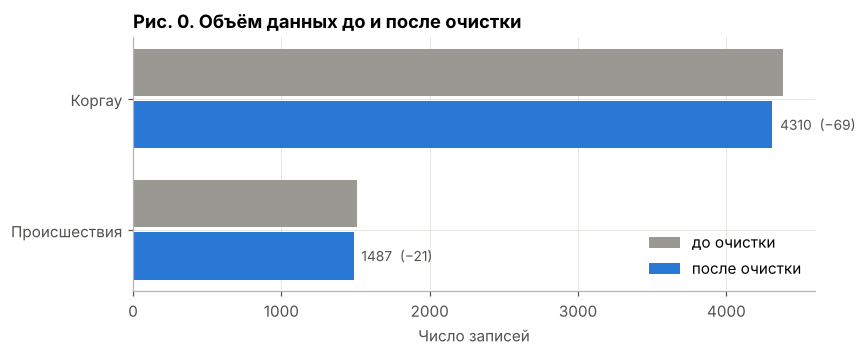

Типы после очистки: datetime64[us] | классы: ['Авария', 'Микротравма', 'Несчастный случай', 'Опасная ситуация']


In [11]:
fig, ax = plt.subplots(figsize=(8, 3))
labels = ["Происшествия", "Коргау"]
before = [rep_i["rows_before"], rep_k["rows_before"]]
after = [rep_i["rows_after"], rep_k["rows_after"]]
y = np.arange(2)
ax.barh(y + .2, before, height=.36, color=MUTED, label="до очистки")
ax.barh(y - .2, after, height=.36, color=MAIN, label="после очистки")
for yy, b, a in zip(y, before, after):
    ax.text(a, yy - .2, f"  {a}  (−{b - a})", va="center", fontsize=9, color="#52514e")
ax.set_yticks(y, labels); ax.set_xlabel("Число записей")
ax.set_title("Рис. 0. Объём данных до и после очистки"); ax.legend(loc="lower right")
plt.show()
print("Типы после очистки:", incidents["date"].dtype, "| классы:", sorted(incidents["type"].unique()))

## 5. Exploratory Data Analysis

### 5.1 Баланс классов

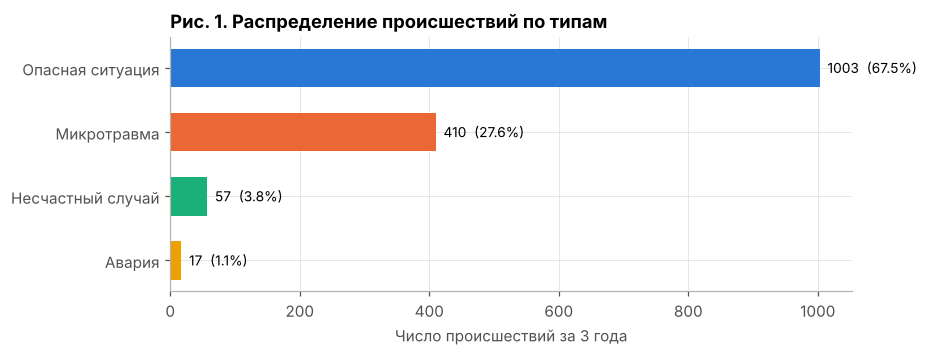

В среднем за год: {'Опасная ситуация': 334.3, 'Микротравма': 136.7, 'Несчастный случай': 19.0, 'Авария': 5.7}


In [12]:
counts = incidents["type"].value_counts().reindex(INCIDENT_TYPES)
fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(counts.index[::-1], counts.values[::-1], color=[TYPE_COLORS[t] for t in counts.index[::-1]], height=.6)
for i, (t, v) in enumerate(zip(counts.index[::-1], counts.values[::-1])):
    ax.text(v, i, f"  {v}  ({v / counts.sum():.1%})", va="center", fontsize=9)
ax.set_xlabel("Число происшествий за 3 года"); ax.set_title("Рис. 1. Распределение происшествий по типам")
plt.show()
print("В среднем за год:", (counts / 3).round(1).to_dict())

**Наблюдение 1.** Классы сильно несбалансированы: опасных ситуаций ≈ 67%, аварий ≈ 1%. Средние значения за год (≈ 334 / 137 / 19 / 6) близки к табл. 8.1 ТЗ.
**Вывод:** для классификации нужны `stratify`, `class_weight` и **macro-F1**. Accuracy здесь обманчива: модель, которая всегда отвечает «опасная ситуация», уже получит 67%.

### 5.2 Динамика во времени (RQ1)

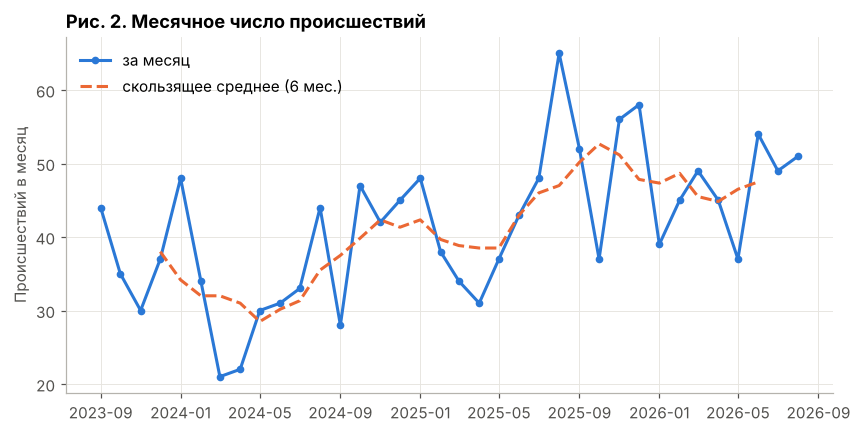

По годам наблюдения (сен–авг): [409, 506, 572] | рост за 2 года: 40%


In [13]:
monthly = monthly_counts(incidents)
fig, ax = plt.subplots()
ax.plot(monthly.index, monthly.values, color=MAIN, marker="o", markersize=4, label="за месяц")
ax.plot(monthly.index, monthly.rolling(6, center=True).mean(), color=PALETTE[1], linewidth=2,
        linestyle="--", label="скользящее среднее (6 мес.)")
ax.set_ylabel("Происшествий в месяц"); ax.set_title("Рис. 2. Месячное число происшествий")
ax.legend(); plt.show()
yearly = monthly.groupby((np.arange(len(monthly)) // 12)).sum()
print("По годам наблюдения (сен–авг):", yearly.tolist(), "| рост за 2 года:", f"{yearly.iloc[-1] / yearly.iloc[0] - 1:.0%}")

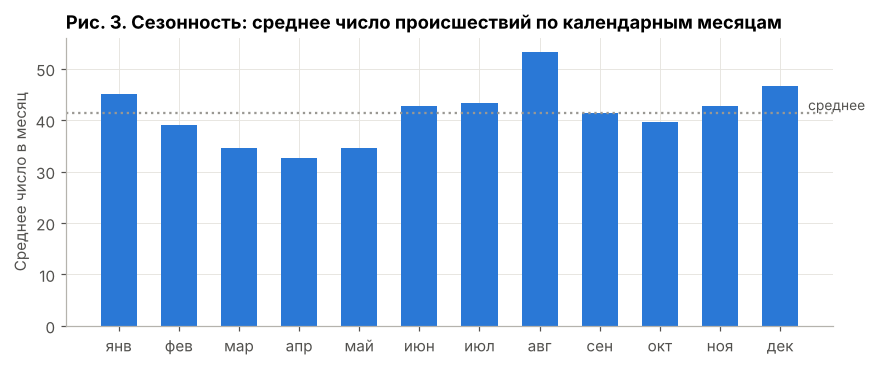

In [14]:
by_month = incidents.groupby(incidents["date"].dt.month).size() / 3
names = ["янв", "фев", "мар", "апр", "май", "июн", "июл", "авг", "сен", "окт", "ноя", "дек"]
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(names, by_month.values, color=MAIN, width=.6)
ax.axhline(by_month.mean(), color=MUTED, linestyle=":", linewidth=1.5)
ax.text(11.4, by_month.mean(), " среднее", va="bottom", fontsize=9, color="#52514e")
ax.set_ylabel("Среднее число в месяц"); ax.set_title("Рис. 3. Сезонность: среднее число происшествий по календарным месяцам")
plt.show()

**Наблюдение 2.** Ряд **растёт**: за третий год происшествий на ≈ 40% больше, чем за первый. Стационарности нет, поэтому модель прогноза должна учитывать тренд.
**Наблюдение 3.** Есть **сезонность**: пики зимой (дек–янв: гололёд, холод) и летом (июль–август: жара, пик строительных и высотных работ), минимум в апреле–мае. Значит, у прогноза должна быть сезонная компонента (SARIMA / Holt-Winters).

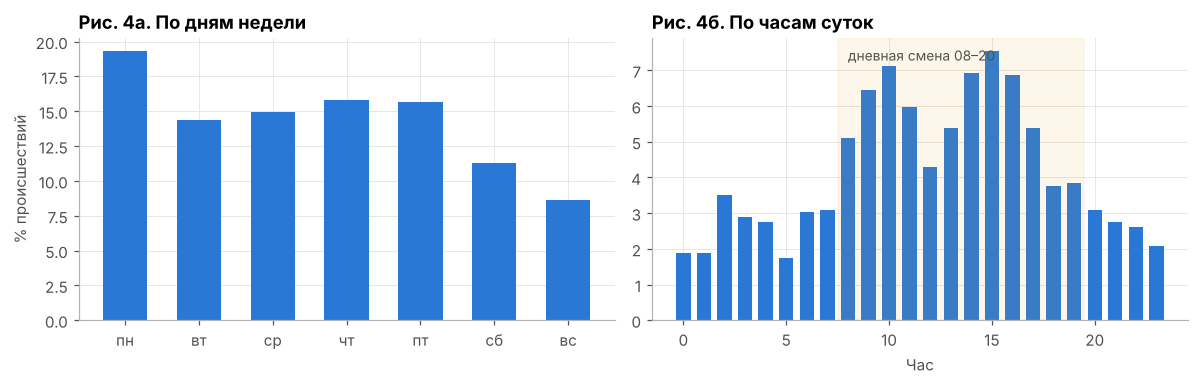

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
wd = incidents["date"].dt.dayofweek.value_counts(normalize=True).sort_index()
axes[0].bar(["пн", "вт", "ср", "чт", "пт", "сб", "вс"], wd.values * 100, color=MAIN, width=.6)
axes[0].set_ylabel("% происшествий"); axes[0].set_title("Рис. 4а. По дням недели")
hr = incidents["date"].dt.hour.value_counts(normalize=True).sort_index()
axes[1].bar(hr.index, hr.values * 100, color=MAIN, width=.7)
axes[1].axvspan(7.5, 19.5, color=PALETTE[3], alpha=.08)
axes[1].text(8, axes[1].get_ylim()[1] * .92, "дневная смена 08–20", fontsize=9, color="#52514e")
axes[1].set_xlabel("Час"); axes[1].set_title("Рис. 4б. По часам суток")
plt.tight_layout(); plt.show()

**Наблюдение 4.** Понедельник — самый опасный день (≈ 19% событий против ≈ 15% в другие будни): возвращение после выходных, «раскачка». Внутри смены два пика, около 10–11 и 15–17 часов (накопление усталости). Это готовые темы для рекомендаций (F-04): целевые инструктажи в понедельник утром, микропаузы во второй половине смены.

### 5.3 Организации: подразделения и подрядчики

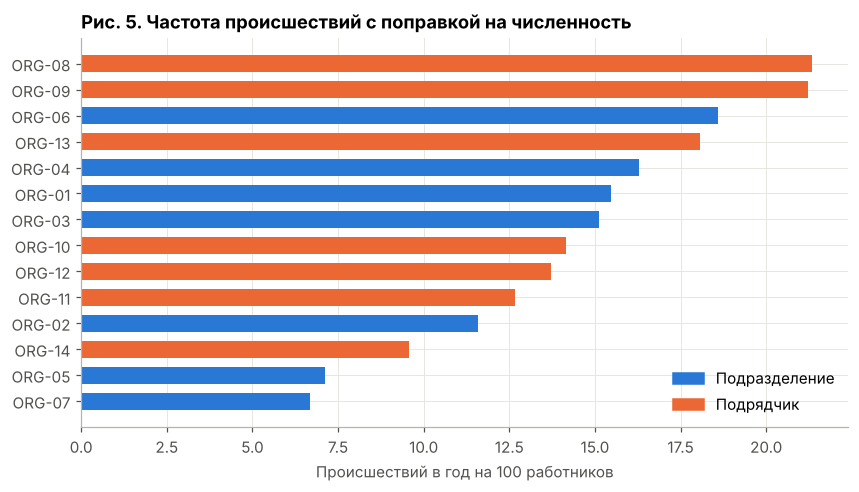

kind
Подразделение    13.0
Подрядчик        15.8
dtype: float64


In [16]:
o = orgs.set_index("org_id")
rate = (incidents.groupby("org_id").size() / 3 / o["headcount"] * 100).sort_values()
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.barh(rate.index, rate.values, color=[KIND_COLORS[o.loc[i, "kind"]] for i in rate.index], height=.65)
ax.set_xlabel("Происшествий в год на 100 работников")
ax.set_title("Рис. 5. Частота происшествий с поправкой на численность")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=k) for k, c in KIND_COLORS.items()], loc="lower right")
plt.show()
print(rate.groupby(o["kind"]).mean().round(1))

**Наблюдение 5.** Сравнивать организации нужно **на 100 работников**: в абсолютных числах большие цеха всегда «впереди». С этой поправкой подрядчики в среднем на ≈ 20% опаснее подразделений, а самые рискованные — буровой и строительно-монтажный подрядчики (ORG-08, ORG-09). Численность (`headcount`) — обязательный признак для risk scoring.

### 5.4 Карта Коргау

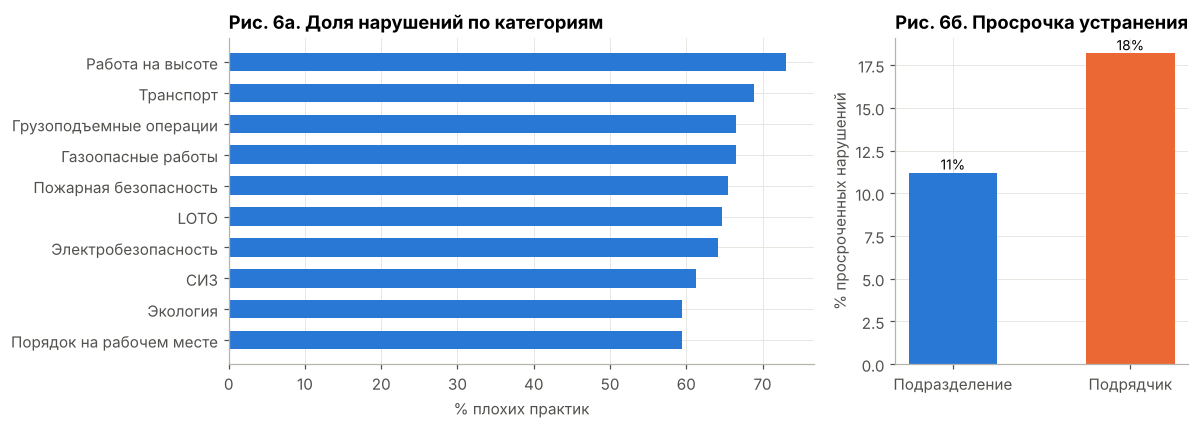

In [17]:
bad = korgau[korgau["is_bad"]]
share = korgau.groupby("category")["is_bad"].mean().sort_values()
overdue = bad.assign(kind=bad["org_id"].map(o["kind"])).groupby("kind")["resolved"].apply(
    lambda s: (s == "Просрочено").mean())
fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [2, 1]})
axes[0].barh(share.index, share.values * 100, color=MAIN, height=.6)
axes[0].set_xlabel("% плохих практик"); axes[0].set_title("Рис. 6а. Доля нарушений по категориям")
axes[1].bar(overdue.index, overdue.values * 100, color=[KIND_COLORS[k] for k in overdue.index], width=.5)
for x, v in enumerate(overdue.values):
    axes[1].text(x, v * 100, f"{v:.0%}", ha="center", va="bottom", fontsize=9)
axes[1].set_ylabel("% просроченных нарушений"); axes[1].set_title("Рис. 6б. Просрочка устранения")
plt.tight_layout(); plt.show()

**Наблюдение 6.** Чаще всего нарушают требования в категориях «Работа на высоте» (≈ 73% наблюдений — плохие практики) и «Транспорт». Подрядчики просрочивают устранение нарушений заметно чаще подразделений (≈ 18% против ≈ 11%). Нарушение, которое не устранили, остаётся «открытой дверью» для происшествия, поэтому `overdue_lag1` идёт в признаки.

### 5.5 Связь Коргау → происшествия (RQ2, гипотеза H1)

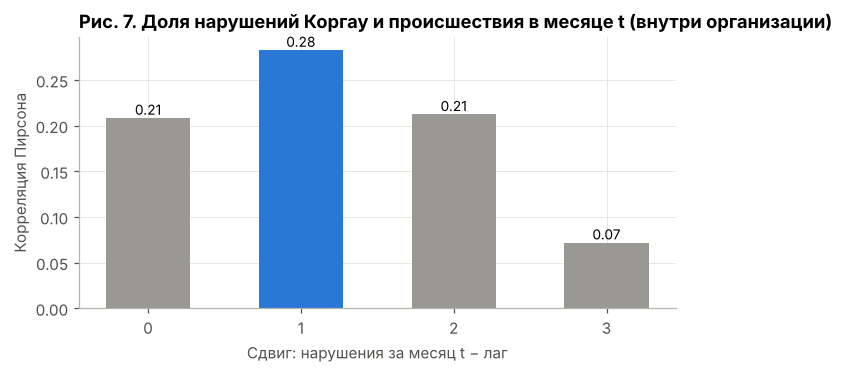

,корреляция
"лаг, мес.",
0,0.208
1,0.283
2,0.212
3,0.072


In [18]:
om = build_org_month(incidents, korgau, orgs)

# Сравниваем организацию саму с собой: вычитаем её среднее (иначе корреляцию дадут
# просто размеры — в большой организации много и нарушений, и происшествий).
full = om.sort_values(["org_id", "month"]).copy()
rows = []
for lag in range(4):
    x = full.groupby("org_id")["bad_share"].shift(lag)
    d = pd.DataFrame({"x": x, "y": full["incidents"], "org": full["org_id"]}).dropna()
    g = d.groupby("org")
    rows.append((lag, (d["x"] - g["x"].transform("mean")).corr(d["y"] - g["y"].transform("mean"))))
lags = pd.DataFrame(rows, columns=["лаг, мес.", "корреляция"]).set_index("лаг, мес.")

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(lags.index.astype(str), lags["корреляция"], color=[MUTED, MAIN, MUTED, MUTED], width=.55)
for i, v in enumerate(lags["корреляция"]):
    ax.text(i, v, f"{v:.2f}", ha="center", va="bottom", fontsize=9)
ax.set_xlabel("Сдвиг: нарушения за месяц t − лаг"); ax.set_ylabel("Корреляция Пирсона")
ax.set_title("Рис. 7. Доля нарушений Коргау и происшествия в месяце t (внутри организации)")
plt.show()
lags.round(3)

**Наблюдение 7 (главное).** Связь сильнее всего при **сдвиге на 1 месяц** (r ≈ 0.28). В тот же месяц она слабее (≈ 0.21), а через 3 месяца почти исчезает. Нарушения **предшествуют** происшествиям, а не просто сопровождают их. Это подтверждает H1 и даёт основание для системы раннего предупреждения (F-13, F-14).
Связь умеренная: Коргау — сигнал, а не приговор. Риск-модель должна сочетать его с историей происшествий.

### 5.6 Тексты описаний (RQ3)

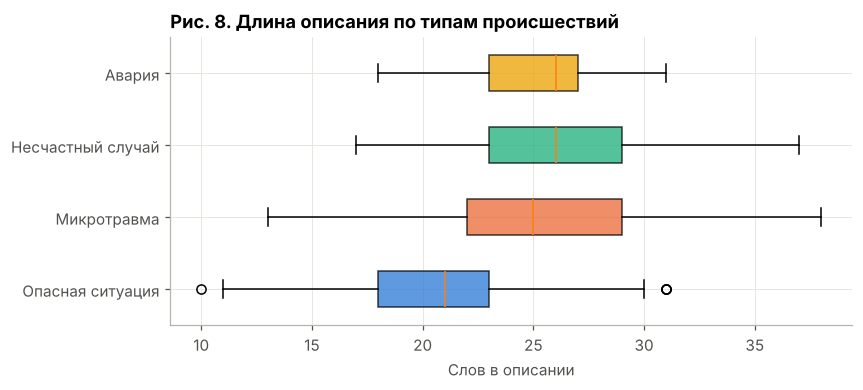

— Опасная ситуация: Согласно рапорту, 02.09.2023 в 18:58 на объекте «Кустовая площадка» газосварщик работал в колодце, сработал газоанализатор.
— Микротравма: По информации мастера смены, 01.09.2023 около 18:42 на объекте «Склад ГСМ» мастер участка управлял автомобилем на промысловой дороге и съехал в кювет. Пострадавший получил ушиб головы, обработано в медпункте.
— Несчастный случай: Во время пусконаладочных работ на объекте «Склад ГСМ» помощник бурильщика превысил скорость на территории объекта. Пострадавший получил сочетанную травму и госпитализирован. Оформлен лист нетрудоспособности.
— Авария: На объекте «Буровая площадка» в 12:07 произошло столкновение двух единиц техники на перекрёстке промысловой дороги. Последствия: повреждение автомобиля и опоры ЛЭП. Участок выведен из эксплуатации до устранения.


In [19]:
incidents["n_words"] = incidents["description"].str.split().str.len()
fig, ax = plt.subplots(figsize=(8, 3.4))
data = [incidents.loc[incidents["type"] == t, "n_words"] for t in INCIDENT_TYPES]
bp = ax.boxplot(data, orientation="horizontal", patch_artist=True, widths=.5)
for patch, t in zip(bp["boxes"], INCIDENT_TYPES):
    patch.set_facecolor(TYPE_COLORS[t]); patch.set_alpha(.75)
ax.set_yticks(range(1, 5), INCIDENT_TYPES); ax.set_xlabel("Слов в описании")
ax.set_title("Рис. 8. Длина описания по типам происшествий")
plt.show()
for t in INCIDENT_TYPES:
    print(f"— {t}: {incidents.loc[incidents['type'] == t, 'description'].iloc[0]}")

**Наблюдение 8.** Сценарий события («упал с лестницы», «сработал газоанализатор») встречается во всех типах. Тип определяют **последствия** («пострадавших нет», «обработано в медпункте», «госпитализирован»). Часть текстов сформулирована неоднозначно («работник обратился в медпункт»). Классификация решаема, но не тривиальна: ошибки ожидаются между микротравмой и НС.

## 6. Признаки и target

В проекте **три задачи**, у каждой свои X и y:

| Задача | y (target) | X (признаки) | Почему этот target |
|---|---|---|---|
| A. Прогноз (F-06) | число происшествий компании в месяц | история ряда: тренд, сезон | ТЗ требует прогноз на 3/6/12 мес. |
| B. Risk scoring (F-12, F-13) | `incidents` организации в месяце *t* | признаки за прошлые месяцы (таблица ниже) | риск = ожидаемое число событий в следующем месяце |
| C. NLP (F-01) | `type` | `description` | автоматическая классификация «молний» |

**Признаки задачи B и их ожидаемое влияние**

| Признак | Смысл | Ожидаемое влияние на target |
|---|---|---|
| `inc_lag1`, `inc_mean3` | происшествия за прошлый месяц и среднее за 3 мес. | + инерция риска |
| `bad_lag1` | число нарушений Коргау за прошлый месяц | + (H1) |
| `bad_share_lag1` | доля плохих практик за прошлый месяц | + (H1, не зависит от числа аудитов) |
| `overdue_lag1` | просроченные нарушения | + неустранённые опасности |
| `is_contractor` | подрядчик или подразделение | + (наблюдение 5) |
| `headcount` | численность | + больше людей — больше экспозиция |

**Проверка data leakage**
- Все признаки B — **лаги**: в начале месяца *t* они уже известны. Нарушения месяца *t* в признаки не входят.
- Для задачи C **нельзя** использовать `cause` и `status`: причину заполняют после расследования, а статус «Расследуется» почти всегда означает тяжёлое событие. В момент регистрации «молнии» этих полей ещё нет.
- Для задачи A сезонность и тренд оцениваются только на train.

In [20]:
om[["org_id", "month", TARGET] + FEATURES].head()

,org_id,month,incidents,inc_lag1,inc_mean3,bad_lag1,bad_share_lag1,overdue_lag1,is_contractor,headcount
0,ORG-01,2023-12-01,2,4.0,4.000000,7.0,0.636364,0.0,0,420
1,ORG-01,2024-01-01,3,2.0,4.000000,7.0,0.368421,2.0,0,420
2,ORG-01,2024-02-01,1,3.0,3.000000,8.0,0.347826,0.0,0,420
3,ORG-01,2024-03-01,1,1.0,2.000000,2.0,0.166667,0.0,0,420
4,ORG-01,2024-04-01,2,1.0,1.666667,11.0,0.523810,3.0,0,420


In [21]:
corr = om[FEATURES + [TARGET]].corr()[TARGET].drop(TARGET).sort_values()
print("Корреляция признаков с target (задача B):")
print(corr.round(2))

Корреляция признаков с target (задача B):
is_contractor    -0.00
bad_share_lag1    0.33
overdue_lag1      0.36
bad_lag1          0.53
headcount         0.53
inc_lag1          0.54
inc_mean3         0.56
Name: incidents, dtype: float64


## 7. Train / Validation / Test

**Задачи A и B (временные данные)** — разбиение **по времени**, без перемешивания. Иначе модель «подсмотрит будущее»:

| Часть | Период | Месяцев |
|---|---|---|
| train | 2023-09 … 2025-08 | 24 |
| validation | 2025-09 … 2026-02 | 6 (подбор гиперпараметров) |
| test | 2026-03 … 2026-08 | 6 (финальная оценка, трогаем один раз) |

**Задача C (тексты)** — stratified 70 / 15 / 15. Стратификация нужна: аварий всего ~17, без неё в test может не попасть ни одной. Тексты не зависят от времени, поэтому случайное разбиение допустимо.

In [22]:
from sklearn.model_selection import train_test_split

print("Задача B, строк по частям:", om["split"].value_counts().to_dict())

monthly_split = split_period(pd.Series(monthly.index, index=monthly.index))
print("Задача A, месяцев:", monthly_split.value_counts().to_dict())

train_txt, tmp = train_test_split(incidents, test_size=.30, stratify=incidents["type"], random_state=42)
val_txt, test_txt = train_test_split(tmp, test_size=.50, stratify=tmp["type"], random_state=42)
pd.DataFrame({p: d["type"].value_counts() for p, d in
              [("train", train_txt), ("val", val_txt), ("test", test_txt)]})

Задача B, строк по частям: {'train': 294, 'val': 84, 'test': 84}
Задача A, месяцев: {'train': 24, 'val': 6, 'test': 6}


,train,val,test
type,,,
Опасная ситуация,701,151,151
Микротравма,287,61,62
Несчастный случай,40,8,9
Авария,12,3,2


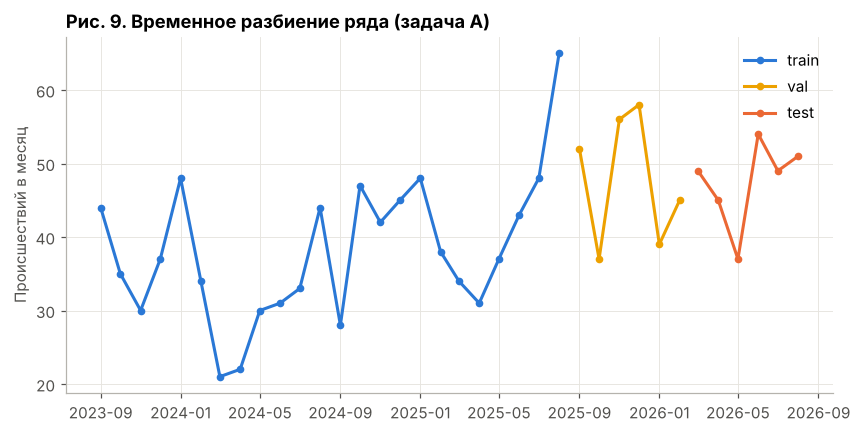

In [23]:
fig, ax = plt.subplots()
colors = {"train": MAIN, "val": PALETTE[3], "test": PALETTE[1]}
for part, color in colors.items():
    m = monthly_split == part
    ax.plot(monthly.index[m], monthly.values[m], color=color, marker="o", markersize=4, label=part)
ax.set_ylabel("Происшествий в месяц"); ax.set_title("Рис. 9. Временное разбиение ряда (задача A)")
ax.legend(); plt.show()

## 8. Научная интерпретация

- **RQ1 (прогноз).** В ряду есть рост (≈ +40% за 2 года) и сезонность «зима + лето». Модель, которая просто повторяет прошлый год (seasonal naive), будет систематически занижать прогноз, поэтому оправданы модели с трендом и сезонностью. Это проверим на baseline-этапе.
- **RQ2 (Коргау → происшествия).** Гипотеза H1 **предварительно подтверждена**: связь максимальна при лаге в 1 месяц (r ≈ 0.28). Значит, рост доли нарушений — ранний сигнал, на который можно ставить pre-alert (F-14). Связь умеренная, поэтому Коргау будет одним признаком из нескольких.
- **RQ3 (тексты).** Тип определяется описанием последствий. Ожидаем высокое качество на частых классах и ошибки на редких (НС, авария), где мало примеров.

**Ограничения.** Данные синтетические, найденные закономерности заложены генератором. Они подтверждают работоспособность методов, но не описывают реальное предприятие. Классы НС и «авария» малы, поэтому метрики по ним будут неустойчивыми.